# Slopegraph Demonstration using Plotnine

This notebook is uses a simulated dataset to build a "slopegraph" in Plotnine. I also use methods from Polars to manipulate the build and manipulate the required data frames.

In [1]:
import polars as pl
from plotnine import *
from great_tables import GT

## A demonstration dataset

In [2]:
results_df = pl.DataFrame(
    {
        'Video': ["Bar charts", "Facets", "Line charts"],
        'Before CTR': [0.038, 0.026, 0.021],
        'After CTR': [0.03, 0.026, 0.046]
    }
)

results_df

Video,Before CTR,After CTR
str,f64,f64
"""Bar charts""",0.038,0.03
"""Facets""",0.026,0.026
"""Line charts""",0.021,0.046


In [3]:
(
    GT(results_df)
    .fmt_percent(columns=['Before CTR', 'After CTR'], decimals=1)
)
    # .gtsave('ctr_table.png')

Video,Before CTR,After CTR
Bar charts,3.8%,3.0%
Facets,2.6%,2.6%
Line charts,2.1%,4.6%


### Long data frame

In [4]:
long_df = (
     results_df
    .unpivot(
        index='Video', 
        variable_name='observation', 
        value_name='CTR'
    )
)

long_df

Video,observation,CTR
str,str,f64
"""Bar charts""","""Before CTR""",0.038
"""Facets""","""Before CTR""",0.026
"""Line charts""","""Before CTR""",0.021
"""Bar charts""","""After CTR""",0.03
"""Facets""","""After CTR""",0.026
"""Line charts""","""After CTR""",0.046


In [5]:
results_long_df = (
     results_df
    .unpivot(
        index='Video', 
        variable_name='observation', 
        value_name='CTR'
    ).with_columns(
        pl.col('observation')
            .str.replace_all(' CTR', '')
            .cast(pl.Enum(['Before', 'After']))
    ).with_columns(
        pct_label=pl.format('{}%', (pl.col('CTR') * 100).round(1).cast(pl.String))
    ).with_columns(
        label=pl.format('{}  {}', pl.col('Video'), pl.col('pct_label'))
    )
)

results_long_df

Video,observation,CTR,pct_label,label
str,enum,f64,str,str
"""Bar charts""","""Before""",0.038,"""3.8%""","""Bar charts 3.8%"""
"""Facets""","""Before""",0.026,"""2.6%""","""Facets 2.6%"""
"""Line charts""","""Before""",0.021,"""2.1%""","""Line charts 2.1%"""
"""Bar charts""","""After""",0.03,"""3.0%""","""Bar charts 3.0%"""
"""Facets""","""After""",0.026,"""2.6%""","""Facets 2.6%"""
"""Line charts""","""After""",0.046,"""4.6%""","""Line charts 4.6%"""


## First steps for the Plotnine visualization

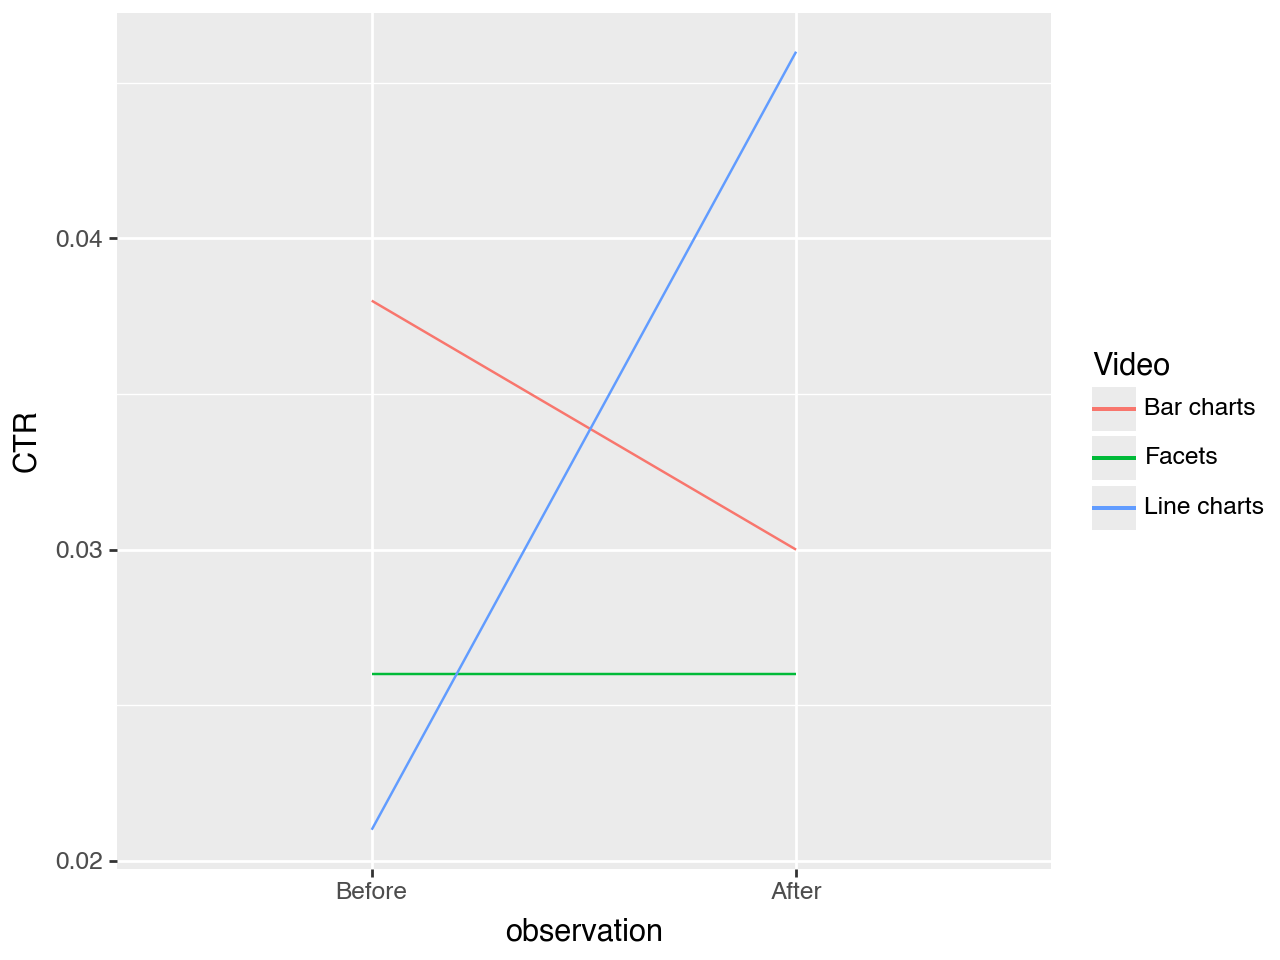

In [6]:
(
    results_long_df
    >>
    ggplot(mapping=aes(x='observation', y='CTR', group='Video'))
    + geom_line(mapping=aes(color='Video'))
)

## Complete Plotnine visualization

In [7]:
after_df = results_long_df.filter(pl.col('observation')=='After')
before_df = results_long_df.filter(pl.col('observation')=='Before')

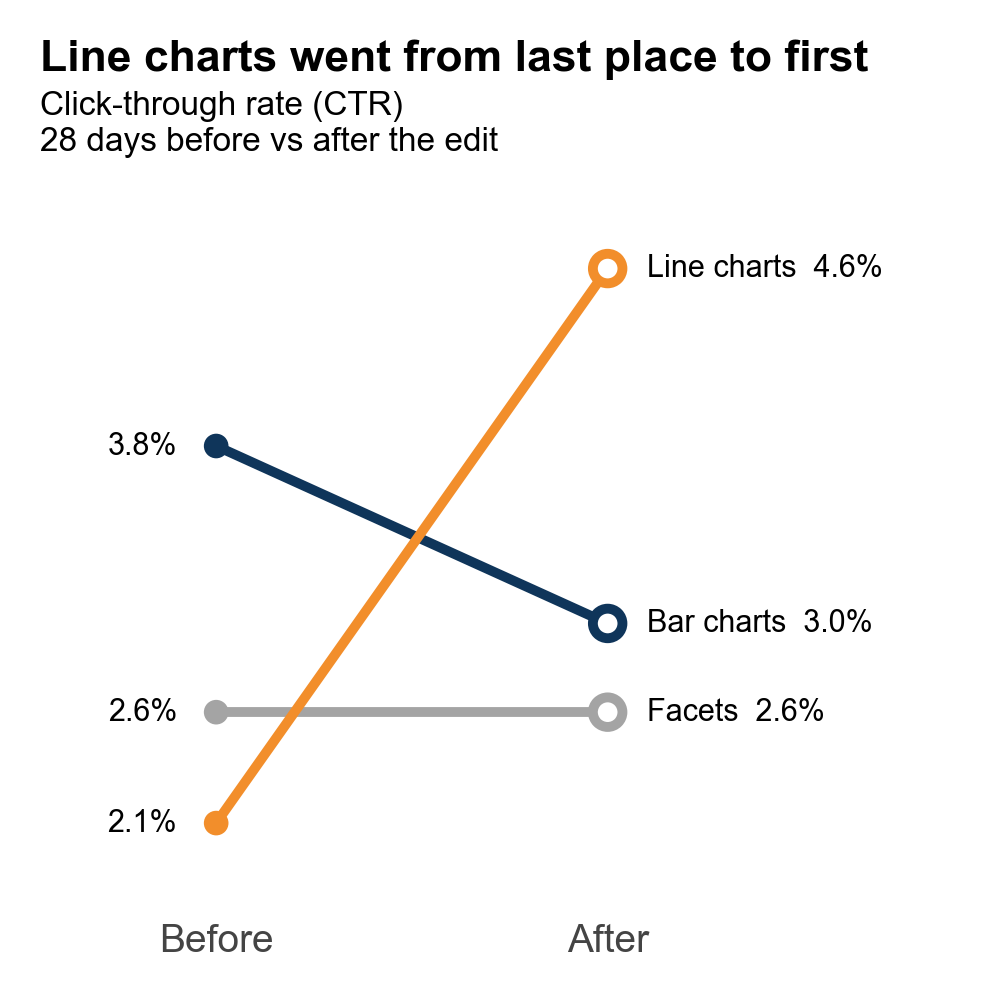

In [8]:
manual_colors = {
    "Line charts": "#f28e2b", 
    "Bar charts": "#0f355a", 
    "Facets": "#a4a4a4"
}

plot_title = "Line charts went from last place to first"
plot_subtitle = "Click-through rate (CTR) \n28 days before vs after the edit"

(
    results_long_df
    >>
    ggplot(aes(x='observation', y='CTR', group='Video'))
    + geom_line(aes(color='Video'), size=2)
    + geom_point(
        aes(color='Video'),
        data=after_df,
        size=4,
        shape='o',
        fill='white',
        stroke=2
    )
    + geom_point(
        aes(color='Video'),
        data=before_df,
        size=4,
        shape='o'
    )
    + geom_text(
        aes(x='observation', label='label'),
        ha='left',
        nudge_x=0.1,
        data=after_df
    )
    + geom_text(
        aes(x='observation', label='pct_label'),
        ha='right',
        nudge_x=-0.1,
        data=before_df
    )
    + labs(
        title=plot_title,
        subtitle=plot_subtitle
    )
    + scale_color_manual(values=manual_colors)
    + scale_x_discrete(expand=(0, 0.35, 0, 0.8))
    + scale_y_continuous(
        limits=(0.018, 0.049)
    )
    + theme_void()
    + theme(
        figure_size=(5, 5),
        plot_margin=0.04,
        text=element_text(family='Arial'),
        plot_title=element_text(size=16, weight='bold', linespacing=1.2),
        plot_title_position='plot',
        plot_subtitle=element_text(size=12, linespacing=1.2),
        axis_title=element_blank(),
        axis_text_x=element_text(color='#444', size=14),
        axis_text_y=element_blank(),
        legend_position='none'
    )
)
    # .save('slope_draft.png', dpi=300)